Second dataset notebook, Pima Indians Diabetes, Mike Hembree

Milestone One needs at least two datasets, so this notebook runs the same six techniques on a second healthcare dataset next to the MIMIC-IV ICU demo. This one is the Pima Indians Diabetes Database from the National Institute of Diabetes and Digestive and Kidney Diseases (Smith et al., 1988), 768 women at least 21 years old of Pima Indian heritage with eight clinical measurements and a 0 or 1 flag for diabetes. It is a good partner for the ICU data since it is also tabular clinical data but with five times as many rows and a different kind of noise.

I set it up as two problems like I did for MIMIC. Weeks 1 to 3 predict plasma glucose (the 2 hour oral glucose tolerance value, a continuous target) from the other measurements, which is basically asking whether cheap bedside numbers can tell you who needs a glucose test. Weeks 4 to 6 predict the diabetes flag from all eight measurements. Same repeated cross validation as the MIMIC summary notebook, five fold repeated six times for regression and stratified five fold repeated three times for classification, with tuning nested inside each fold. The csv is a copy of the public dataset, and three separate GitHub copies matched exactly.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [2]:
# load the data, zeros in the lab and body measurements are really missing values
raw = pd.read_csv('pima_diabetes.csv')
print(raw.shape, raw['Outcome'].value_counts().to_dict())
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df = raw.copy()
df[zero_cols] = df[zero_cols].replace(0, np.nan)
miss = df[zero_cols].isna().mean().mul(100).round(1)
print(miss.to_dict())
df.describe().round(2)


(768, 9) {0: 500, 1: 268}
{'Glucose': 0.7, 'BloodPressure': 4.6, 'SkinThickness': 29.6, 'Insulin': 48.7, 'BMI': 1.4}


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,763.00,733.00,541.00,394.00,757.00,768.00,768.00,768.00
mean,3.85,121.69,72.41,29.15,155.55,32.46,0.47,33.24,0.35
std,3.37,30.54,12.38,10.48,118.78,6.92,0.33,11.76,0.48
min,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1.00,99.00,64.00,22.00,76.25,27.50,0.24,24.00,0.00
50%,3.00,117.00,72.00,29.00,125.00,32.30,0.37,29.00,0.00
75%,6.00,141.00,80.00,36.00,190.00,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


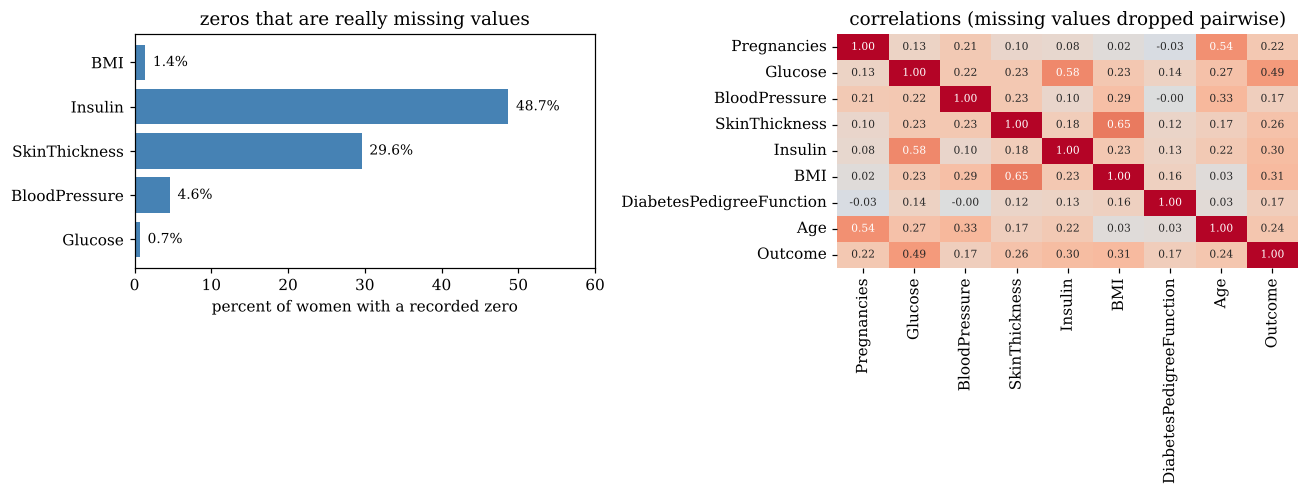

{'Pregnancies': 0.13, 'DiabetesPedigreeFunction': 0.14, 'BloodPressure': 0.22, 'SkinThickness': 0.23, 'BMI': 0.23, 'Age': 0.27, 'Outcome': 0.49, 'Insulin': 0.58, 'Glucose': 1.0}
{'BloodPressure': 0.17, 'DiabetesPedigreeFunction': 0.17, 'Pregnancies': 0.22, 'Age': 0.24, 'SkinThickness': 0.26, 'Insulin': 0.3, 'BMI': 0.31, 'Glucose': 0.49, 'Outcome': 1.0}


In [3]:
# eda figure, share of missing values and correlations on the cleaned data
fig, ax = plt.subplots(1, 2, figsize = (12, 4.6))
ax[0].barh(miss.index, miss.values, color = 'steelblue')
for i, v in enumerate(miss.values):
    ax[0].text(v + 1, i, str(v) + '%', va = 'center', fontsize = 9)
ax[0].set_xlim(0, 60)
ax[0].set_xlabel('percent of women with a recorded zero')
ax[0].set_title('zeros that are really missing values')
sns.heatmap(df.corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0, ax = ax[1], annot_kws = {'size': 7}, cbar = False)
ax[1].set_title('correlations (missing values dropped pairwise)')
plt.tight_layout()
plt.savefig('figs/pima_eda.png', dpi = 200)
plt.show()
print(df.corr()['Glucose'].round(2).sort_values().to_dict())
print(df.corr()['Outcome'].round(2).sort_values().to_dict())


The big thing from the eda is that zeros in glucose, blood pressure, skin thickness, insulin and bmi can't be real, nobody has a blood pressure of zero, so they're missing values coded as zero. Insulin is missing for 48.7 percent of women and skin thickness for 29.6 percent. I recoded them as missing and fill with the median inside each pipeline so the folds stay clean. Two correlated pairs show up, skin thickness with bmi (0.65) and pregnancies with age (0.54), and glucose lines up with both insulin (0.58) and the diabetes flag (0.49), so I'd expect glucose to run the classification models.

In [4]:
# set up the two problems, imputation happens inside each pipeline so folds stay clean
reg_cols = ['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
clf_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

rmask = df['Glucose'].notna()
X = df.loc[rmask, reg_cols]
y = df.loc[rmask, 'Glucose']
Xc = df[clf_cols]
yc = df['Outcome'].astype(int)
print(X.shape, Xc.shape)

cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 6, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)


(763, 7) (768, 8)


In [5]:
# does keeping insulin and skin thickness (about half missing) help or hurt, scaled logistic regression
def auc_cv(cols):
    m = make_pipeline(SimpleImputer(strategy = 'median'), StandardScaler(), LogisticRegression(max_iter = 5000))
    return cross_validate(m, Xc[cols], yc, cv = cv_clf, scoring = 'roc_auc', n_jobs = 2)['test_score'].mean()

print('all eight:', round(auc_cv(clf_cols), 3))
print('without insulin and skin thickness:', round(auc_cv([c for c in clf_cols if c not in ['Insulin', 'SkinThickness']]), 3))
print('without insulin only:', round(auc_cv([c for c in clf_cols if c != 'Insulin']), 3))


all eight: 0.836
without insulin and skin thickness: 0.839


without insulin only: 0.838


Dropping insulin and skin thickness barely changes the auc (0.839 without both against 0.836 with all eight), so the heavy imputation isn't hurting the model, but it also means those two columns aren't adding much. I kept all eight so the comparison with the other weeks stays simple.

In [6]:
# regression, weeks 1 to 3, sweep the number of variables or components for selection, pcr and plsr
def pre():
    return [SimpleImputer(strategy = 'median'), StandardScaler()]

def cv_reg_score(model):
    r = cross_validate(model, X, y, cv = cv_reg, scoring = ('r2', 'neg_root_mean_squared_error'), return_train_score = True, n_jobs = 2)
    return {'train r2': r['train_r2'].mean(), 'cv r2': r['test_r2'].mean(), 'cv rmse': -r['test_neg_root_mean_squared_error'].mean(), 'rmse sd': r['test_neg_root_mean_squared_error'].std()}

sweep = []
for k in range(1, 8):
    if k < 7:
        for d in ['forward', 'backward']:
            m = make_pipeline(*pre(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = k, direction = d, cv = 5), LinearRegression())
            sweep.append({'method': d + ' selection', 'k': k, **cv_reg_score(m)})
    sweep.append({'method': 'pcr', 'k': k, **cv_reg_score(make_pipeline(*pre(), PCA(k), LinearRegression()))})
    sweep.append({'method': 'plsr', 'k': k, **cv_reg_score(make_pipeline(*pre(), PLSRegression(k)))})
sweep = pd.DataFrame(sweep)
sweep.to_csv('figs/pima_wk3_sweep.csv', index = False)
sweep.pivot_table(index = 'k', columns = 'method', values = 'cv rmse').round(3)


method,backward selection,forward selection,pcr,plsr
k,,,,
1,27.728,27.728,27.964,26.761
2,26.932,26.980,27.944,26.425
3,26.536,26.516,27.245,26.437
4,26.432,26.408,26.613,26.444
5,26.390,26.385,26.414,26.446
6,26.414,26.414,26.442,26.445
7,NaN,NaN,26.445,26.445


In [7]:
# regression comparison table, all techniques on the same footing
best = sweep.loc[sweep.groupby('method')['cv rmse'].idxmin()].set_index('method')['k'].to_dict()
print(best)
reg_models = {
    'linear (baseline)': make_pipeline(*pre(), LinearRegression()),
    'week 1 interactions only': make_pipeline(*pre(), PolynomialFeatures(2, interaction_only = True, include_bias = False), LinearRegression()),
    'week 1 degree 2': make_pipeline(*pre(), PolynomialFeatures(2, include_bias = False), LinearRegression()),
    'week 2 ridge': make_pipeline(*pre(), RidgeCV(alphas = np.logspace(-3, 3, 50))),
    'week 2 lasso': make_pipeline(*pre(), LassoCV(alphas = np.logspace(-3, 1, 50), max_iter = 10000)),
    'week 2 elastic net': make_pipeline(*pre(), ElasticNetCV(alphas = np.logspace(-3, 1, 50), l1_ratio = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1], max_iter = 10000)),
    'week 3 forward selection': make_pipeline(*pre(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = int(best['forward selection']), direction = 'forward', cv = 5), LinearRegression()),
    'week 3 backward selection': make_pipeline(*pre(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = int(best['backward selection']), direction = 'backward', cv = 5), LinearRegression()),
    'week 3 pcr': make_pipeline(*pre(), PCA(int(best['pcr'])), LinearRegression()),
    'week 3 plsr': make_pipeline(*pre(), PLSRegression(int(best['plsr']))),
}
rows = []
for name, m in reg_models.items():
    rows.append({'model': name, **cv_reg_score(m)})
reg_tab = pd.DataFrame(rows)
reg_tab.to_csv('figs/pima_regression_summary.csv', index = False)
reg_tab.round(3)


{'backward selection': 5, 'forward selection': 5, 'pcr': 5, 'plsr': 2}


,model,train r2,cv r2,cv rmse,rmse sd
0,linear (baseline),0.268,0.244,26.445,1.337
1,week 1 interactions only,0.301,0.204,27.104,1.582
2,week 1 degree 2,0.327,0.191,27.319,1.873
3,week 2 ridge,0.267,0.245,26.435,1.311
4,week 2 lasso,0.267,0.246,26.410,1.315
5,week 2 elastic net,0.267,0.246,26.416,1.308
6,week 3 forward selection,0.267,0.247,26.385,1.320
7,week 3 backward selection,0.267,0.247,26.390,1.323
8,week 3 pcr,0.263,0.246,26.414,1.275
9,week 3 plsr,0.267,0.245,26.425,1.286


Insulin is what forward and backward selection grab first, and the two methods agree again like they did on the ICU data. All the weeks 2 and 3 methods land within 0.003 of each other on cv r squared (0.244 to 0.247) and the polynomial versions are worse (0.19 and 0.20). Compared with MIMIC this is a much milder polynomial penalty, there are 35 columns for degree 2 against roughly 610 training rows, where on MIMIC it was 65 columns against 112 rows.

In [8]:
# holdout check and what lasso and selection keep, same 80 20 split idea as the other notebooks
def hold(name, model):
    model.fit(X_train, y_train)
    p = np.ravel(model.predict(X_test))
    return {'model': name, 'test r2': r2_score(y_test, p), 'test rmse': mean_squared_error(y_test, p) ** 0.5}

print(pd.DataFrame([hold(k, v) for k, v in reg_models.items()]).round(3))

lasso_fit = make_pipeline(*pre(), LassoCV(alphas = np.logspace(-3, 1, 50), max_iter = 10000)).fit(X, y)
print('lasso alpha:', round(lasso_fit[-1].alpha_, 4))
print(pd.Series(lasso_fit[-1].coef_, index = reg_cols).round(3).to_dict())
ridge_fit = make_pipeline(*pre(), RidgeCV(alphas = np.logspace(-3, 3, 50))).fit(X, y)
print('ridge alpha:', round(ridge_fit[-1].alpha_, 3))
for d in ['forward', 'backward']:
    for k in [1, 2, 3]:
        s = make_pipeline(*pre(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = k, direction = d, cv = 5)).fit(X, y)
        print(d, k, list(X.columns[s[-1].get_support()]))
print(PolynomialFeatures(2, include_bias = False).fit(X.fillna(0)).n_output_features_, PolynomialFeatures(2, interaction_only = True, include_bias = False).fit(X.fillna(0)).n_output_features_, 'columns from', X.shape[1], 'predictors,', int(len(X) * 0.8), 'training rows')


                       model  test r2  test rmse
0          linear (baseline)    0.301     25.420
1   week 1 interactions only    0.201     27.163
2            week 1 degree 2    0.251     26.306
3               week 2 ridge    0.301     25.422
4               week 2 lasso    0.299     25.454
5         week 2 elastic net    0.301     25.420
6   week 3 forward selection    0.305     25.343
7  week 3 backward selection    0.305     25.343
8                 week 3 pcr    0.314     25.170
9                week 3 plsr    0.312     25.210
lasso alpha: 0.4942
{'Pregnancies': 0.0, 'BloodPressure': 2.955, 'SkinThickness': 0.658, 'Insulin': 10.791, 'BMI': 3.084, 'DiabetesPedigreeFunction': 1.648, 'Age': 5.472}
ridge alpha: 59.636
forward 1 ['Insulin']


forward 2 ['Insulin', 'Age']
forward 3 ['Insulin', 'BMI', 'Age']


backward 1 ['Insulin']


backward 2 ['Insulin', 'Age']


backward 3 ['Insulin', 'BMI', 'Age']
35 28 columns from 7 predictors, 610 training rows


Regularization does basically nothing here, the lasso, ridge and elastic net cv r squared values are 0.245 to 0.246 against 0.244 for plain linear regression. That's the bias variance story from the other side, with 610 rows and only 7 predictors there isn't much variance to cut. The holdout split agrees on the ordering within noise, the best test r squared is 0.31 (pcr and plsr) against 0.30 for linear.

In [9]:
# classification, weeks 4 to 6, tuning is nested inside each outer fold
rf_grid = {'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]}
clf_models = {
    'week 4 logistic, unscaled': make_pipeline(SimpleImputer(strategy = 'median'), LogisticRegression(max_iter = 5000)),
    'week 4 logistic, scaled': make_pipeline(*pre(), LogisticRegression(max_iter = 5000)),
    'week 4 logistic, cv regularized': make_pipeline(*pre(), LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, scoring = 'roc_auc', max_iter = 5000)),
    'week 4 logistic, cv balanced': make_pipeline(*pre(), LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, scoring = 'roc_auc', max_iter = 5000, class_weight = 'balanced')),
    'week 5 linear svm, tuned': GridSearchCV(make_pipeline(*pre(), SVC(kernel = 'linear', class_weight = 'balanced')), {'svc__C': [0.001, 0.01, 0.1, 1, 10]}, scoring = 'roc_auc', cv = 5),
    'week 5 rbf svm, tuned': GridSearchCV(make_pipeline(*pre(), SVC(kernel = 'rbf', class_weight = 'balanced')), {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.03, 0.1, 0.3]}, scoring = 'roc_auc', cv = 5),
    'week 6 decision tree, tuned': GridSearchCV(make_pipeline(SimpleImputer(strategy = 'median'), DecisionTreeClassifier(class_weight = 'balanced', random_state = 0)), {'decisiontreeclassifier__max_depth': [2, 3, 4, 5, 6], 'decisiontreeclassifier__min_samples_leaf': [1, 3, 5, 10]}, scoring = 'roc_auc', cv = 5),
    'week 6 random forest, default': make_pipeline(SimpleImputer(strategy = 'median'), RandomForestClassifier(n_estimators = 300, random_state = 0)),
    'week 6 random forest, tuned': GridSearchCV(make_pipeline(SimpleImputer(strategy = 'median'), RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0)), {'randomforestclassifier__' + k: v for k, v in rf_grid.items()}, scoring = 'roc_auc', cv = 5),
}
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
rows = []
for name, m in clf_models.items():
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = scoring, n_jobs = 2)
    rows.append({'model': name, 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
    print(name, round(rows[-1]['auc'], 3))
clf_tab = pd.DataFrame(rows)
clf_tab.to_csv('figs/pima_classification_summary.csv', index = False)
clf_tab.round(3)


week 4 logistic, unscaled 0.836
week 4 logistic, scaled 0.836


week 4 logistic, cv regularized 0.837


week 4 logistic, cv balanced 0.837


week 5 linear svm, tuned 0.836


week 5 rbf svm, tuned 0.836


week 6 decision tree, tuned 0.792


week 6 random forest, default 0.827


week 6 random forest, tuned 0.84


,model,auc,auc sd,recall,precision,f1,accuracy
0,"week 4 logistic, unscaled",0.836,0.027,0.563,0.715,0.628,0.767
1,"week 4 logistic, scaled",0.836,0.027,0.563,0.716,0.629,0.768
2,"week 4 logistic, cv regularized",0.837,0.025,0.552,0.718,0.622,0.766
3,"week 4 logistic, cv balanced",0.837,0.025,0.723,0.630,0.671,0.752
4,"week 5 linear svm, tuned",0.836,0.024,0.711,0.639,0.671,0.756
5,"week 5 rbf svm, tuned",0.836,0.026,0.734,0.628,0.675,0.753
6,"week 6 decision tree, tuned",0.792,0.029,0.792,0.558,0.651,0.706
7,"week 6 random forest, default",0.827,0.029,0.601,0.675,0.633,0.758
8,"week 6 random forest, tuned",0.840,0.027,0.784,0.617,0.689,0.752


Every linear style classifier ties at an auc of 0.836 or 0.837 whether or not I scale, regularize, or switch to an svm, and the cv standard deviation across folds is about 0.025, so none of those differences mean anything. The tuned random forest is on top at 0.840 and the default forest at 0.827. The single tree is the clear loser at 0.792. Balanced class weights are the one thing that moves a metric, recall goes from 0.56 to 0.72 for logistic regression and f1 from 0.63 to 0.67 with auc unchanged.

In [10]:
# tree depth sweep, training auc against cv auc
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    m = make_pipeline(SimpleImputer(strategy = 'median'), DecisionTreeClassifier(max_depth = d, class_weight = 'balanced', random_state = 0))
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = 'roc_auc', return_train_score = True, n_jobs = 2)
    rows.append({'depth': 'none' if d is None else d, 'train auc': r['train_score'].mean(), 'cv auc': r['test_score'].mean()})
depth_tab = pd.DataFrame(rows)
depth_tab.to_csv('figs/pima_tree_depth.csv', index = False)
depth_tab.round(3)


,depth,train auc,cv auc
0,1,0.719,0.700
1,2,0.792,0.754
2,3,0.843,0.797
3,4,0.880,0.791
4,5,0.911,0.777
5,6,0.937,0.759
6,8,0.975,0.722
7,10,0.992,0.704
8,none,1.000,0.688


Same overfitting picture as the ICU data. Training auc runs up to 1.00 for an unlimited tree while cv auc peaks at 0.80 around depth 3 and slides to 0.69.

In [11]:
# tuned settings on the full data, forest importance and logistic coefficients
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

gs = GridSearchCV(make_pipeline(SimpleImputer(strategy = 'median'), RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0)), {'randomforestclassifier__' + k: v for k, v in rf_grid.items()}, scoring = 'roc_auc', cv = 5, n_jobs = 2).fit(Xc, yc)
print('rf best:', gs.best_params_, round(gs.best_score_, 3))
perm = []
for tr, te in StratifiedKFold(5, shuffle = True, random_state = 3).split(Xc, yc):
    f = clone_fit = make_pipeline(SimpleImputer(strategy = 'median'), RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0, **{k.split('__')[1]: v for k, v in gs.best_params_.items()})).fit(Xc.iloc[tr], yc.iloc[tr])
    p = permutation_importance(f, Xc.iloc[te], yc.iloc[te], scoring = 'roc_auc', n_repeats = 20, random_state = 0)
    perm.append(p.importances_mean)
perm = pd.Series(np.mean(perm, axis = 0), index = clf_cols).sort_values(ascending = False)
print(perm.round(3).to_dict())

lr = clf_models['week 4 logistic, cv regularized'].fit(Xc, yc)
print('logistic cv C:', lr[-1].C_)
print(pd.Series(lr[-1].coef_[0], index = clf_cols).round(3).sort_values().to_dict())
svm_rbf = GridSearchCV(make_pipeline(*pre(), SVC(kernel = 'rbf', class_weight = 'balanced')), {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.03, 0.1, 0.3]}, scoring = 'roc_auc', cv = 5, n_jobs = 2).fit(Xc, yc)
print('rbf best:', svm_rbf.best_params_, round(svm_rbf.best_score_, 3))


rf best: {'randomforestclassifier__max_depth': 5, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 3} 0.842


{'Glucose': 0.126, 'BMI': 0.047, 'Age': 0.025, 'Insulin': 0.011, 'DiabetesPedigreeFunction': 0.007, 'Pregnancies': 0.003, 'SkinThickness': 0.002, 'BloodPressure': -0.002}


logistic cv C: [0.33598183]
{'BloodPressure': -0.096, 'Insulin': -0.081, 'SkinThickness': 0.043, 'Age': 0.156, 'DiabetesPedigreeFunction': 0.28, 'Pregnancies': 0.401, 'BMI': 0.614, 'Glucose': 1.102}


rbf best: {'svc__C': 1, 'svc__gamma': 0.03} 0.84


Glucose does most of the work in the forest (shuffling it costs about 0.13 auc), then bmi (0.05) and age (0.03), and blood pressure is at zero. The cv chosen logistic regression has glucose as its biggest coefficient too (1.10 on standardized features), then bmi. The forest preferred depth 5 with square root features, a bit deeper than on MIMIC, which fits having five times as many rows.

In [12]:
# single stratified holdout split for comparison with the weeks 4 to 6 notebooks
def hold_clf(name, model):
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    s = model.decision_function(Xc_test) if hasattr(model, 'decision_function') else model.predict_proba(Xc_test)[:, 1]
    return {'model': name, 'accuracy': accuracy_score(yc_test, pred), 'recall': recall_score(yc_test, pred), 'f1': f1_score(yc_test, pred), 'auc': roc_auc_score(yc_test, s)}

pick = ['week 4 logistic, scaled', 'week 4 logistic, cv balanced', 'week 5 rbf svm, tuned', 'week 6 decision tree, tuned', 'week 6 random forest, tuned']
print(pd.DataFrame([hold_clf(k, clf_models[k]) for k in pick]).round(3))
print('test rows:', len(yc_test), 'positives:', int(yc_test.sum()))


                          model  accuracy  recall     f1    auc
0       week 4 logistic, scaled     0.708   0.500  0.545  0.813
1  week 4 logistic, cv balanced     0.727   0.704  0.644  0.810
2         week 5 rbf svm, tuned     0.740   0.722  0.661  0.810
3   week 6 decision tree, tuned     0.682   0.852  0.652  0.784
4   week 6 random forest, tuned     0.760   0.778  0.694  0.812
test rows: 154 positives: 54


With 154 test women and 54 positives the holdout aucs (0.78 to 0.81) are close to the cv values (0.79 to 0.84), which is a lot more agreement than I got between holdout and cv on the 140 stay ICU data. That supports blaming the MIMIC disagreements on the tiny test set.